In [1]:
from nuscenes.nuscenes import NuScenes
from lidar import Lidar

nusc = NuScenes(
    version='v1.0-mini',
    dataroot=r'C:\Users\rajab\OneDrive\nuscenes-devkit-master\v1.0-mini',
    verbose=True
)

lidar = Lidar(nusc)

Loading NuScenes tables for version v1.0-mini...
23 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor,
31206 ego_pose,
8 log,
10 scene,
404 sample,
31206 sample_data,
18538 sample_annotation,
4 map,
Done loading in 0.492 seconds.
Reverse indexing ...
Done reverse indexing in 0.2 seconds.


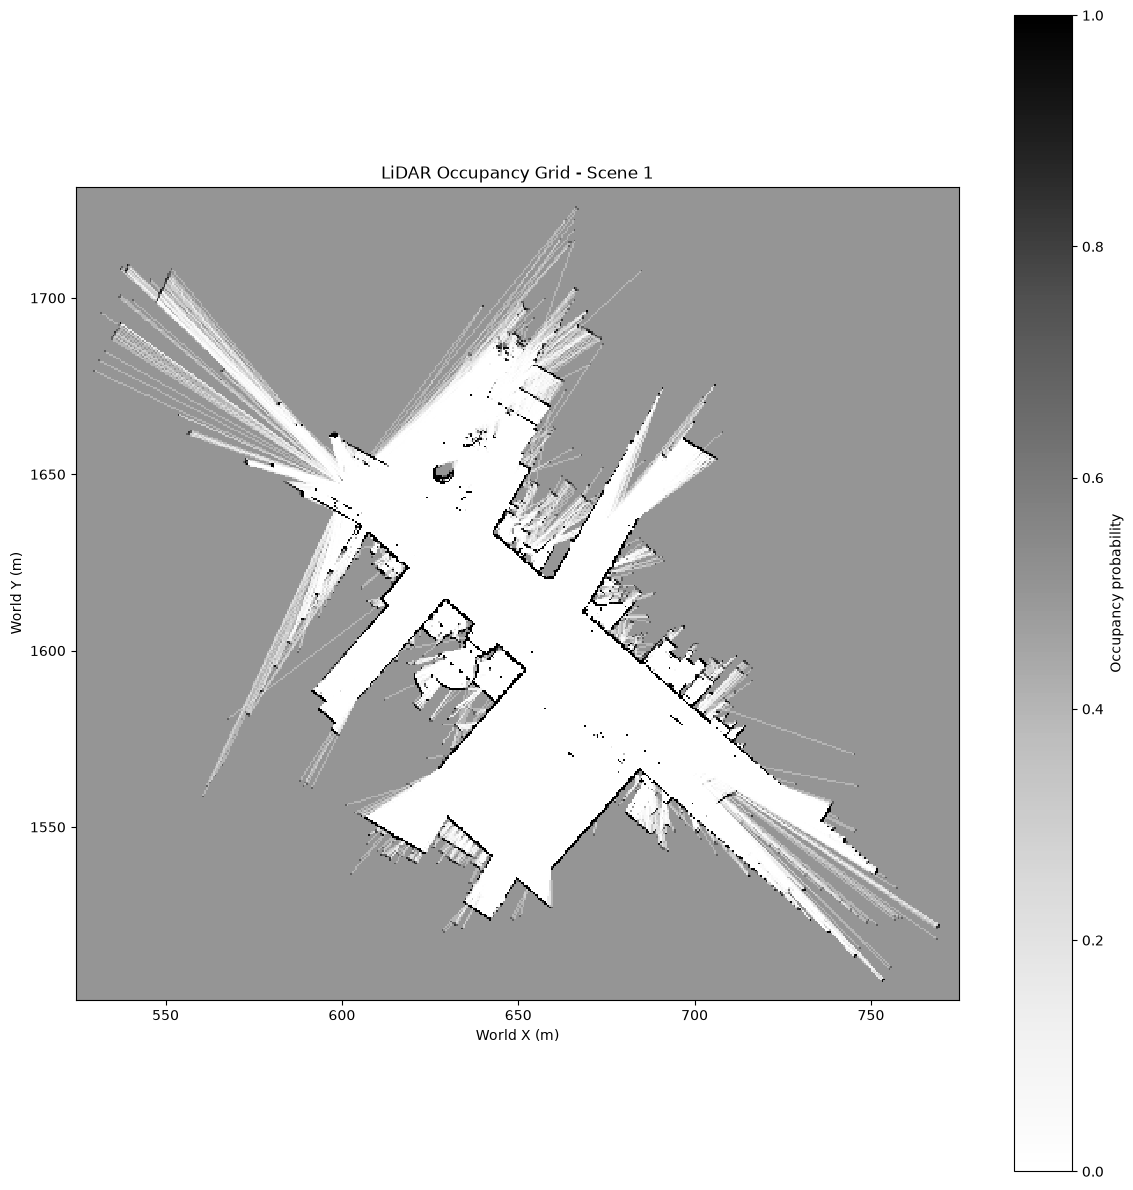

In [2]:
from lidar import *
import numpy as np
import matplotlib.pyplot as plt
from bresenham import bresenham

# =========================================================
# CONFIGURATION
# =========================================================

SCENE_NUMBER = 1
SAMPLE_NUMBER = 0
MODE = "scene"  # "scene" or "sample"

RESOLUTION = 0.5       # meters per cell
MARGIN = 5.0           # meters around map boundaries

P_OCCUPIED = 0.7
P_FREE = 0.4
PRIOR = 0.5

LOG_PRIOR = np.log(PRIOR / (1.0 - PRIOR))
LOG_OCCUPIED = np.log(P_OCCUPIED / (1.0 - P_OCCUPIED)) - LOG_PRIOR
LOG_FREE = np.log(P_FREE / (1.0 - P_FREE))

# =========================================================
# LOAD LIDAR DATA
# =========================================================

if MODE == "scene":
    lidar_points, lidar_pose = lidar.get_all_points(SCENE_NUMBER)

    lidar_points = np.asarray(lidar_points, dtype=float)
    lidar_pose = np.asarray(lidar_pose, dtype=float)

elif MODE == "sample":
    x_world, y_world = lidar.get_lidar_sample(SCENE_NUMBER, SAMPLE_NUMBER)

    lidar_points = np.column_stack((x_world, y_world))

    pose = np.asarray(lidar.get_lidar_pose(SCENE_NUMBER, SAMPLE_NUMBER),dtype=float)

    lidar_pose = np.tile(pose, (len(lidar_points), 1))

else:
    raise ValueError("MODE must be 'scene' or 'sample'.")

if lidar_points.ndim != 2 or lidar_points.shape[1] != 2:
    raise ValueError("lidar_points must have shape (N, 2).")

if lidar_pose.ndim != 2 or lidar_pose.shape[1] != 2:
    raise ValueError("lidar_pose must have shape (N, 2).")

if len(lidar_points) != len(lidar_pose):
    raise ValueError("Each point must have a corresponding sensor pose.")

valid = (np.all(np.isfinite(lidar_points), axis=1)& np.all(np.isfinite(lidar_pose), axis=1))

lidar_points = lidar_points[valid]
lidar_pose = lidar_pose[valid]

if len(lidar_points) == 0:
    raise ValueError("No valid LiDAR points available.")

# =========================================================
# MAP BOUNDS AND GRID INITIALIZATION
# =========================================================

coordinates = np.vstack((lidar_points, lidar_pose))

x_min = np.floor((coordinates[:, 0].min() - MARGIN) / RESOLUTION) * RESOLUTION
y_min = np.floor((coordinates[:, 1].min() - MARGIN) / RESOLUTION) * RESOLUTION
x_max = coordinates[:, 0].max() + MARGIN
y_max = coordinates[:, 1].max() + MARGIN

grid_x = int(np.ceil((x_max - x_min) / RESOLUTION)) + 1
grid_y = int(np.ceil((y_max - y_min) / RESOLUTION)) + 1

logodds = np.zeros((grid_x, grid_y), dtype=np.float32)

# Convert world coordinates to grid indices.
def world_to_grid(points):
    return np.floor((points - np.array([x_min, y_min])) / RESOLUTION).astype(np.int64)

endpoints = world_to_grid(lidar_points)
origins = world_to_grid(lidar_pose)

# =========================================================
# OCCUPANCY GRID INVERSE SENSOR MODEL
# =========================================================

for origin, endpoint in zip(origins, endpoints):
    sx, sy = origin
    ex, ey = endpoint

    # Skip rays whose origin or endpoint is outside the grid.
    if not (0 <= sx < grid_x and 0 <= sy < grid_y):
        continue

    if not (0 <= ex < grid_x and 0 <= ey < grid_y):
        continue

    ray = list(bresenham(int(sx), int(sy), int(ex), int(ey)))

    if not ray:
        continue

    # Cells before the measured endpoint are free.
    for gx, gy in ray[:-1]:
        if 0 <= gx < grid_x and 0 <= gy < grid_y:
            logodds[gx, gy] += LOG_FREE

    # The measured endpoint is occupied.
    logodds[ex, ey] += LOG_OCCUPIED

# Limit log-odds to avoid numerical overflow and excessive confidence.
np.clip(logodds, -20.0, 20.0, out=logodds)

# =========================================================
# CONVERT LOG-ODDS TO OCCUPANCY PROBABILITIES
# =========================================================

probability = 1.0 / (1.0 + np.exp(-logodds))

# =========================================================
# VISUALIZATION
# =========================================================

plt.figure(figsize=(12, 12))

plt.imshow(
    probability.T,
    cmap="Greys",
    vmin=0.0,
    vmax=1.0,
    origin="lower",
    interpolation="nearest",
    extent=[
        x_min,
        x_min + (grid_x - 1) * RESOLUTION,
        y_min,
        y_min + (grid_y - 1) * RESOLUTION
    ],
    aspect="equal"
)

plt.xlabel("World X (m)")
plt.ylabel("World Y (m)")
plt.title(f"LiDAR Occupancy Grid - Scene {SCENE_NUMBER}")
plt.colorbar(label="Occupancy probability")
plt.tight_layout()
plt.show()
